# DSA 405 Project Milestone 4: Do states with more distributed solar pay different residential electricity prices?

**Author:** Tanmayi Kurra (Unity ID `tkurra`)  |  **Course:** DSA 405, Fall 2026

**Question.** Do U.S. states with more distributed solar pay different average residential electricity prices?

**What this notebook does.** It runs from the raw files in `data/raw/` to the final figure, with no manual steps:

1. Rebuild the clean EIA price table from the raw EIA file (P2 logic) and check it matches the committed clean file.
2. Load the Berkeley Lab solar state-year summary. If the 252 MB zip is in `data/raw/`, rebuild the summary from it and check it matches; if not, use the committed summary.
3. Join the two tables (left join from EIA, one-to-one) and run the verification checks from P3.
4. Estimate the price-solar relationship four ways, from the simplest comparison to the one that controls most.
5. Draw the final figure and save every number the report cites to `results/p4_results.json`.

**How to run.** From the repository root: `pip install -r requirements.txt`, then Kernel → Restart & Run All. Without the zip it takes about 10 seconds; with the zip it also streams 4 million rows and takes about a minute on my test machine.

How the zip was obtained, and the ethics and legality checks, are in the P3 notebook (`DSA405_002_FA26_P3_tkurra.ipynb`). This notebook does not download anything.

In [15]:
import hashlib, json, shutil, subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

# Everything is relative to the repository root, so a fresh clone works without edits.
RAW, CLEAN, FIG, RES = Path("data/raw"), Path("data/clean"), Path("figures"), Path("results")
if not (RAW / "eia_retail_sales_raw.csv").exists():
    raise FileNotFoundError("Start Jupyter from the repository root (the folder that contains data/).")
for d in (FIG, RES):
    d.mkdir(exist_ok=True)

ZIP_PATH      = RAW / "LBNL_distributed_solar_dataset_public.zip"
MANIFEST      = RAW / "MANIFEST_LBNL.json"
CSV_MEMBER    = "TTS_LBNL_public_file_28-Jul-2026_all.csv"
EXPECTED_ROWS = 3_995_665
RESULTS = {}      # every number the report cites is stored here and written to results/p4_results.json
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.3.4


## Step 1. EIA residential price: raw file to clean table

Same logic as P2: keep the 50 states and DC, drop the 11 regional and national aggregate codes, rename columns, fix types, and fill the single missing price (Alaska, 2016) by linear interpolation. The result must equal the clean file committed in `data/clean/`.

In [16]:
raw = pd.read_csv(RAW / "eia_retail_sales_raw.csv")

STATES = ['AL','AK','AZ','AR','CA','CO','CT','DE','FL','GA','HI','ID','IL','IN','IA','KS','KY','LA','ME','MD','MA','MI',
          'MN','MS','MO','MT','NE','NV','NH','NJ','NM','NY','NC','ND','OH','OK','OR','PA','RI','SC','SD','TN','TX','UT',
          'VT','VA','WA','WV','WI','WY','DC']
is_state = raw["stateid"].isin(STATES)
eia = (raw[is_state]
       .rename(columns={"period": "year", "stateid": "state_id", "stateDescription": "state_name",
                        "sectorid": "sector_id", "sectorName": "sector_name",
                        "price": "price_cents_kwh", "price-units": "price_units"})
       .reset_index(drop=True))
n_missing = int(eia["price_cents_kwh"].isna().sum())
eia["price_cents_kwh"] = eia.groupby("state_id")["price_cents_kwh"].transform(lambda s: s.interpolate())

print(f"raw rows {len(raw)} | aggregate rows dropped {int((~is_state).sum())} | clean rows {len(eia)} | "
      f"missing prices filled {n_missing}")

committed = pd.read_csv(CLEAN / "eia_retail_sales_clean.csv")
pd.testing.assert_frame_equal(
    eia[["year", "state_id", "state_name", "price_cents_kwh"]].astype({"state_id": object, "state_name": object}),
    committed[["year", "state_id", "state_name", "price_cents_kwh"]],
    check_dtype=False, atol=1e-9)
print("Rebuilt EIA table matches data/clean/eia_retail_sales_clean.csv")
RESULTS["eia"] = {"raw_rows": len(raw), "aggregate_rows_dropped": int((~is_state).sum()),
                  "clean_rows": len(eia), "missing_prices_filled": n_missing,
                  "price_min": float(eia["price_cents_kwh"].min()), "price_max": float(eia["price_cents_kwh"].max())}

raw rows 1550 | aggregate rows dropped 275 | clean rows 1275 | missing prices filled 1
Rebuilt EIA table matches data/clean/eia_retail_sales_clean.csv


## Step 2. Berkeley Lab solar: one row per state and year

The public file has one row per installed system (3,995,665 rows). I load only four columns, never `city` or `zip_code`. Rows are dropped for three stated reasons (storage-only systems with no PV, a size of -1/0/missing, an unusable state or year), and every row is counted so that kept + dropped = read. Cumulative capacity is the running total of installed kW per state, starting in each state's first year.

In [17]:
USECOLS = ["state", "installation_date", "PV_system_size_DC", "technology_type"]
FIRST_YEAR_OK, LAST_YEAR, EIA_FIRST_YEAR = 1990, 2025, 2001

def sha256_of(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def read_tts(zip_path, chunksize=500_000):
    # The zip uses Deflate64, which Python's zipfile cannot read, so stream it through the system `unzip`.
    proc = subprocess.Popen(["unzip", "-p", str(zip_path), CSV_MEMBER], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    try:
        for ch in pd.read_csv(proc.stdout, usecols=USECOLS, chunksize=chunksize,
                              dtype={"state": str, "technology_type": str, "installation_date": str}):
            yield ch
    finally:
        proc.stdout.close()
    if proc.wait() != 0:
        raise RuntimeError("unzip failed: " + proc.stderr.read().decode(errors="replace"))

def aggregate_tts(zip_path):
    acct = dict(rows_read=0, dropped_storage_only=0, dropped_bad_state=0, dropped_bad_size=0,
                dropped_outside_years=0, kept=0, kept_tech_redacted=0)
    parts = []
    for ch in read_tts(zip_path):
        acct["rows_read"] += len(ch)
        tech  = ch["technology_type"].astype(str).str.strip().str.lower()
        state = ch["state"].astype(str).str.strip().str.upper()
        size  = pd.to_numeric(ch["PV_system_size_DC"], errors="coerce")
        year  = pd.to_numeric(ch["installation_date"].astype(str).str[:4], errors="coerce")
        storage   = tech.eq("storage-only")
        bad_state = ~storage & ~state.str.fullmatch(r"[A-Z]{2}")
        bad_size  = ~storage & ~bad_state & ~(size > 0)
        bad_year  = ~storage & ~bad_state & ~bad_size & ~year.between(FIRST_YEAR_OK, LAST_YEAR)
        keep      = ~(storage | bad_state | bad_size | bad_year)
        acct["dropped_storage_only"]  += int(storage.sum())
        acct["dropped_bad_state"]     += int(bad_state.sum())
        acct["dropped_bad_size"]      += int(bad_size.sum())
        acct["dropped_outside_years"] += int(bad_year.sum())
        acct["kept"]                  += int(keep.sum())
        acct["kept_tech_redacted"]    += int((keep & tech.eq("redacted")).sum())
        parts.append(pd.DataFrame({"state": state[keep], "year": year[keep].astype(int), "kw": size[keep]})
                     .groupby(["state", "year"], as_index=False).agg(kw_added=("kw", "sum"), n_added=("kw", "size")))
    assert acct["rows_read"] == EXPECTED_ROWS, f"read {acct['rows_read']:,} rows, expected {EXPECTED_ROWS:,}"
    assert acct["kept"] + sum(v for k, v in acct.items() if k.startswith("dropped_")) == acct["rows_read"], acct
    added = pd.concat(parts).groupby(["state", "year"], as_index=False).sum()
    # A state-year with no installs is a real zero, so build the full grid before taking the running total.
    grid = pd.MultiIndex.from_product([sorted(added["state"].unique()),
                                       range(min(int(added["year"].min()), EIA_FIRST_YEAR), LAST_YEAR + 1)],
                                      names=["state", "year"])
    cap = added.set_index(["state", "year"]).reindex(grid, fill_value=0).reset_index()
    cap["capacity_kw_cum"] = cap.groupby("state")["kw_added"].cumsum()
    cap["systems_cum"]     = cap.groupby("state")["n_added"].cumsum()
    return cap, acct

cap_committed = pd.read_csv(CLEAN / "tts_state_year_capacity.csv")
acct = json.loads((CLEAN / "tts_accounting.json").read_text())

if ZIP_PATH.exists():
    manifest = json.loads(MANIFEST.read_text())
    assert ZIP_PATH.stat().st_size == manifest["bytes"] and sha256_of(ZIP_PATH) == manifest["sha256"], \
        "The zip in data/raw/ is not the file this project used (size or SHA-256 differs)."
    cap, acct_new = aggregate_tts(ZIP_PATH)
    pd.testing.assert_frame_equal(cap.reset_index(drop=True), cap_committed, check_dtype=False, rtol=1e-9)
    assert acct_new == acct
    print("SOURCE: rebuilt from the zip. SHA-256 verified, and the result equals the committed summary.")
else:
    cap = cap_committed
    print("SOURCE: zip not found in data/raw/, so using the committed summary data/clean/tts_state_year_capacity.csv")

print(f"{len(cap)} state-year rows, {cap['state'].nunique()} jurisdictions, years {cap['year'].min()}-{cap['year'].max()}")
print("Row accounting:", acct)
RESULTS["solar_accounting"] = acct

SOURCE: zip not found in data/raw/, so using the committed summary data/clean/tts_state_year_capacity.csv
756 state-year rows, 27 jurisdictions, years 1998-2025
Row accounting: {'rows_read': 3995665, 'dropped_storage_only': 52922, 'dropped_bad_state': 0, 'dropped_bad_size': 4913, 'dropped_outside_years': 0, 'kept': 3937830, 'kept_tech_redacted': 230106}


## Step 3. Join and verify

**Left join from EIA** on `(state_id, year)`, `validate="one_to_one"`. The question is about price, so every state-year with a price must stay: an inner join would drop the 24 jurisdictions that have no solar data (600 price rows) and make a 27-state result look national. Missing capacity stays `NA`, never 0, because "not in this dataset" is not the same as "no solar".

In [18]:
TERRITORIES = {"PR", "VI", "GU", "AS", "MP"}
cap_join = cap.rename(columns={"state": "state_id"})[["state_id", "year", "capacity_kw_cum", "systems_cum"]]
only_right = sorted(set(cap_join["state_id"]) - set(eia["state_id"]))
N_EXPECTED = len(eia)

merged = eia[["state_id", "state_name", "year", "price_cents_kwh"]].merge(
    cap_join, how="left", on=["state_id", "year"], validate="one_to_one", indicator=True)
print(merged.shape, merged["_merge"].value_counts().to_dict(), "| solar-file jurisdictions not in EIA:", only_right)

def verify(df, n_expected, acct, only_right):
    fails = []
    if len(df) != n_expected:                                        # fan-out or silent row loss
        fails.append(f"row count {len(df)} != expected {n_expected}")
    if df.duplicated(["state_id", "year"]).any():                    # a state counted twice in a year
        fails.append("duplicate (state_id, year) keys")
    if not (df.groupby("state_id").size() == df["year"].nunique()).all():   # wrong grain
        fails.append("some state does not have one row per year")
    if (df["capacity_kw_cum"].dropna() < 0).any():                   # the -1 sentinel summed as real kW
        fails.append("negative capacity")
    if not df["price_cents_kwh"].between(1, 100).all():              # unit or parsing error
        fails.append("price outside 1-100 cents/kWh")
    cov = df.dropna(subset=["capacity_kw_cum"]).sort_values(["state_id", "year"])
    if (cov.groupby("state_id")["capacity_kw_cum"].diff().dropna() < 0).any():   # cumulative total going down
        fails.append("cumulative capacity decreases within a state")
    if not df.groupby("state_id")["capacity_kw_cum"].apply(lambda s: s.isna().mean()).isin([0.0, 1.0]).all():
        fails.append("a state is matched in some years but not others")   # half-matched state
    if set(only_right) - TERRITORIES:                                # real state lost by a left join
        fails.append(f"solar states missing from EIA: {sorted(set(only_right) - TERRITORIES)}")
    if acct["kept"] + sum(v for k, v in acct.items() if k.startswith("dropped_")) != acct["rows_read"]:
        fails.append("aggregation row accounting does not reconcile")
    return fails

failures = verify(merged, N_EXPECTED, acct, only_right)
assert not failures, failures
dup = pd.concat([merged, merged.iloc[[0]]], ignore_index=True)
neg = merged.copy()
neg.loc[neg[neg["capacity_kw_cum"].notna() & (neg["year"] == neg["year"].max())].index[0], "capacity_kw_cum"] = -1
print("All checks passed on the real data.")
print("Mutation test, duplicated row ->", verify(dup, N_EXPECTED, acct, only_right))
print("Mutation test, capacity of -1 ->", verify(neg, N_EXPECTED, acct, only_right))

covered = merged.groupby("state_id")["capacity_kw_cum"].apply(lambda s: s.notna().all())
RESULTS["join"] = {"rows": len(merged), "matched": int((merged["_merge"] == "both").sum()),
                   "unmatched_eia_only": int((merged["_merge"] == "left_only").sum()),
                   "jurisdictions_with_solar": int(covered.sum()), "jurisdictions_without_solar": int((~covered).sum()),
                   "without_solar_list": sorted(covered[~covered].index)}
print(RESULTS["join"])

(1275, 7) {'both': 675, 'left_only': 600, 'right_only': 0} | solar-file jurisdictions not in EIA: []
All checks passed on the real data.
Mutation test, duplicated row -> ['row count 1276 != expected 1275', 'duplicate (state_id, year) keys', 'some state does not have one row per year']
Mutation test, capacity of -1 -> ['negative capacity', 'cumulative capacity decreases within a state']
{'rows': 1275, 'matched': 675, 'unmatched_eia_only': 600, 'jurisdictions_with_solar': 27, 'jurisdictions_without_solar': 24, 'without_solar_list': ['AK', 'AL', 'GA', 'HI', 'IA', 'ID', 'IN', 'KS', 'KY', 'LA', 'MI', 'MO', 'MS', 'MT', 'NC', 'ND', 'NE', 'NV', 'OK', 'SC', 'SD', 'TN', 'WV', 'WY']}


## Step 4. Estimates, from simplest to most controlled

Capacity is on a log10 scale because it spans five orders of magnitude (0.7 MW to 17,793 MW in 2023), so each slope below is **cents/kWh per tenfold increase in cumulative capacity**. Only the 27 jurisdictions with solar data are used; the other 24 are left out of every estimate and the report says so. The log is undefined at zero, so the 53 state-years where a state's cumulative capacity is still 0 (all early years, 2001 to 2010) are dropped from the model data, leaving 622 state-years; the end of Step 4 repeats model D without this restriction.

| Model | Compares | Question it answers | What it cannot rule out |
|---|---|---|---|
| A. One year, across states | State vs state, in one year | Do high-solar states have different prices today? | Anything else that differs between states (fuel mix, grid, costs, policy) |
| B. A without California | Same, 26 states | Is it just California? | The same |
| C. State fixed effects | Each state against its own average | Do prices differ when a state has more solar than usual? | Anything that rises over time everywhere (inflation, fuel prices): solar and nominal prices both trend up |
| D. State + year fixed effects | Each state against its own average, with year-wide shocks removed | Does a state's price move differently from other states' when its solar grows? | Anything that changes inside a state at the same time as its solar (policy, rates) |

D is then repeated with two other defensible choices (log10(1+MW) so that zero is allowed, and 2011-2025 only, when every state has capacity above zero) to see how much the answer depends on them. Standard errors for C and D are clustered by state. With only 27 clusters those can be too narrow, so D also gets a state-level bootstrap interval (2,000 resamples of whole states).

In [19]:
covered_rows = merged.dropna(subset=["capacity_kw_cum"]).copy()
covered_rows["mw"] = covered_rows["capacity_kw_cum"] / 1000
zero_cap = covered_rows[covered_rows["mw"] <= 0]                 # log10(0) is undefined
d = covered_rows[covered_rows["mw"] > 0].copy()
d["log_mw"] = np.log10(d["mw"])
print(f"{len(covered_rows)} covered state-years; {len(zero_cap)} dropped with zero cumulative capacity "
      f"(years {zero_cap['year'].min()}-{zero_cap['year'].max()}, {zero_cap['state_id'].nunique()} states); {len(d)} used")
assert len(covered_rows) == 675 and len(d) == 622 and d["state_id"].nunique() == 27

def cross_section(df):
    r = stats.linregress(df["log_mw"], df["price_cents_kwh"])
    t = stats.t.ppf(0.975, len(df) - 2)
    return dict(n=len(df), slope=r.slope, lo=r.slope - t * r.stderr, hi=r.slope + t * r.stderr,
                r=r.rvalue, p=r.pvalue, spearman=stats.spearmanr(df["log_mw"], df["price_cents_kwh"])[0])

cs = {y: cross_section(d[d["year"] == y]) for y in range(2001, 2026)}
print("A. Cross-section slope (cents/kWh per 10x capacity), selected years")
print(pd.DataFrame({y: cs[y] for y in (2005, 2010, 2015, 2020, 2023, 2025)}).T.round(3).to_string())
print(f"\nSlope is positive in {sum(v['slope'] > 0 for v in cs.values())} of {len(cs)} years; "
      f"CI excludes 0 in {sum(v['lo'] > 0 for v in cs.values())} of {len(cs)} years")

d23 = d[d["year"] == 2023]
a = cs[2023]
b = cross_section(d23[d23["state_id"] != "CA"])
loo = [cross_section(d23[d23["state_id"] != s])["slope"] for s in d23["state_id"]]
print(f"\nB. 2023 without California: slope {b['slope']:.2f}, r {b['r']:.2f}, p {b['p']:.2f}, CI [{b['lo']:.2f}, {b['hi']:.2f}]")
print(f"   Dropping any one state in 2023: slope ranges {min(loo):.2f} to {max(loo):.2f}")

grp = pd.factorize(d["state_id"])[0]
def fe(formula):
    m = smf.ols(formula, d).fit(cov_type="cluster", cov_kwds={"groups": grp})
    ci = m.conf_int().loc["log_mw"]
    return dict(slope=float(m.params["log_mw"]), lo=float(ci[0]), hi=float(ci[1]), p=float(m.pvalues["log_mw"]))
c = fe("price_cents_kwh ~ log_mw + C(state_id)")
dd = fe("price_cents_kwh ~ log_mw + C(state_id) + C(year)")
print(f"\nC. State fixed effects:        slope {c['slope']:.2f}, 95% CI [{c['lo']:.2f}, {c['hi']:.2f}], p {c['p']:.3f}")
print(f"D. State + year fixed effects: slope {dd['slope']:.2f}, 95% CI [{dd['lo']:.2f}, {dd['hi']:.2f}], p {dd['p']:.3f}")

# Bootstrap for D: resample whole states. The panel lost 53 early rows, so demean state and year effects iteratively.
sid, yid = pd.factorize(d["state_id"])[0], (d["year"] - d["year"].min()).to_numpy()
xv, yv = d["log_mw"].to_numpy(), d["price_cents_kwh"].to_numpy()
rows_of = [np.where(sid == k)[0] for k in range(27)]
NY = int(yid.max()) + 1
def demean2(v, g1, n1, g2, n2):
    v = v.astype(float).copy()
    for _ in range(500):
        before = v.copy()
        with np.errstate(invalid="ignore", divide="ignore"):
            v -= (np.bincount(g1, v, n1) / np.bincount(g1, minlength=n1))[g1]
            v -= (np.bincount(g2, v, NY) / np.bincount(g2, minlength=NY))[g2]
        if np.abs(v - before).max() < 1e-12: break
    return v
def twoway_slope(draw):
    idx = np.concatenate([rows_of[k] for k in draw])
    g1 = np.repeat(np.arange(len(draw)), [len(rows_of[k]) for k in draw])   # each resampled copy is its own cluster
    xd, yd = demean2(xv[idx], g1, len(draw), yid[idx], NY), demean2(yv[idx], g1, len(draw), yid[idx], NY)
    return float((xd * yd).sum() / (xd * xd).sum())
assert abs(twoway_slope(np.arange(27)) - dd["slope"]) < 1e-6, "demeaned slope must equal the regression slope"
rng = np.random.default_rng(405)
boot = np.array([twoway_slope(rng.integers(0, 27, 27)) for _ in range(2000)])
blo, bhi = np.percentile(boot, [2.5, 97.5])
print(f"   Bootstrap 95% interval for D: [{blo:.2f}, {bhi:.2f}]  (2,000 resamples of the 27 states, seed 405)")

# Size of the within-state change that D can distinguish from zero: a doubling of capacity is log10(2) = 0.301
print(f"   A doubling of capacity (+0.301 on the log10 scale) is estimated at {dd['slope'] * np.log10(2):+.2f} cents/kWh "
      f"(CI {dd['lo'] * np.log10(2):+.2f} to {dd['hi'] * np.log10(2):+.2f})")

# Robustness for D: change the two choices that could matter (how zero is handled, and which years are used).
def d_variant(df, transform):
    df = df.copy(); df["x"] = transform(df["mw"])
    m_ = smf.ols("price_cents_kwh ~ x + C(state_id) + C(year)", df).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(df["state_id"])[0]})
    ci_ = m_.conf_int().loc["x"]
    return dict(n=len(df), slope=float(m_.params["x"]), lo=float(ci_[0]), hi=float(ci_[1]), p=float(m_.pvalues["x"]))
d_log1p  = d_variant(covered_rows, lambda v: np.log10(1 + v))                       # defined at zero: keeps all 675 rows
d_2011   = d_variant(d[d["year"] >= 2011], np.log10)                                # every state has capacity > 0 from 2011
d_2011_1 = d_variant(covered_rows[covered_rows["year"] >= 2011], lambda v: np.log10(1 + v))
print("\nRobustness for D (state + year effects):")
for lab, v in [("main: log10 MW, 622 rows", dd), ("log10(1+MW), all 675 rows", d_log1p),
               ("log10 MW, 2011-2025 only", d_2011), ("log10(1+MW), 2011-2025 only", d_2011_1)]:
    print(f"  {lab:32s} n={v.get('n', len(d)):3d}  slope {v['slope']:+.2f}  95% CI [{v['lo']:+.2f}, {v['hi']:+.2f}]  p {v['p']:.3f}")
_v = (dd, d_log1p, d_2011, d_2011_1)
print(f"  -> positive in {sum(v['slope'] > 0 for v in _v)} of 4; interval includes 0 in {sum(v['lo'] <= 0 for v in _v)} of 4; "
      f"interval entirely below 0 in {sum(v['hi'] < 0 for v in _v)} of 4.")

RESULTS["estimates"] = {"D_log1p_all_rows": d_log1p, "D_2011_on": d_2011, "D_log1p_2011_on": d_2011_1, "zero_capacity_state_years_dropped": int(len(zero_cap)),
    "A_2023": a, "B_2023_no_CA": b, "leave_one_out_2023_min": min(loo), "leave_one_out_2023_max": max(loo),
    "A_by_year": {str(y): cs[y] for y in (2005, 2010, 2015, 2020, 2023, 2025)},
    "A_positive_years": int(sum(v["slope"] > 0 for v in cs.values())), "A_ci_excludes_zero_years": int(sum(v["lo"] > 0 for v in cs.values())),
    "C_state_fe": c, "D_two_way_fe": dd, "D_bootstrap_ci": [float(blo), float(bhi)],
    "n_state_years_used": len(d), "n_covered_state_years": len(covered_rows), "n_states": int(d["state_id"].nunique())}

675 covered state-years; 53 dropped with zero cumulative capacity (years 2001-2010, 13 states); 622 used
A. Cross-section slope (cents/kWh per 10x capacity), selected years
         n  slope     lo     hi      r      p  spearman
2005  21.0  0.906 -0.121  1.933  0.390  0.080     0.290
2010  26.0  0.315 -0.623  1.252  0.140  0.495     0.166
2015  27.0  1.471  0.191  2.750  0.428  0.026     0.285
2020  27.0  2.039  0.216  3.863  0.418  0.030     0.410
2023  27.0  2.714 -0.086  5.514  0.371  0.057     0.344
2025  27.0  3.257  0.727  5.787  0.469  0.014     0.448

Slope is positive in 24 of 25 years; CI excludes 0 in 15 of 25 years

B. 2023 without California: slope 1.98, r 0.27, p 0.19, CI [-1.02, 4.98]
   Dropping any one state in 2023: slope ranges 1.98 to 3.12

C. State fixed effects:        slope 1.56, 95% CI [1.23, 1.89], p 0.000
D. State + year fixed effects: slope 0.22, 95% CI [-0.41, 0.85], p 0.493
   Bootstrap 95% interval for D: [-0.34, 0.91]  (2,000 resamples of the 27 states, s

## Step 5. Context numbers the report cites

Who is in the solar data, how concentrated it is, and where the install counts drop at the end of the series.

In [20]:
share = cap.groupby("state")["n_added"].sum().sort_values(ascending=False)
share = (share / share.sum())
print("Share of all systems in the 27 jurisdictions:\n", share.head(5).round(3).to_string())
installs = cap.groupby("year")["n_added"].sum()
print("\nSystems installed per year:\n", installs.loc[2021:2025].to_string())
cap23 = d23.set_index("state_id")["mw"]
print(f"\n2023 capacity range: {cap23.min():.1f} MW ({cap23.idxmin()}) to {cap23.max():,.0f} MW ({cap23.idxmax()})")
print("Price range among the 27 in 2023:", d23["price_cents_kwh"].min(), "to", d23["price_cents_kwh"].max())
RESULTS["context"] = {"share_top5": share.head(5).round(4).to_dict(),
                      "installs_2021_2025": {int(k): int(v) for k, v in installs.loc[2021:2025].items()},
                      "cap_2023_min_mw": [cap23.idxmin(), float(cap23.min())], "cap_2023_max_mw": [cap23.idxmax(), float(cap23.max())]}

Share of all systems in the 27 jurisdictions:
 state
CA    0.563
AZ    0.085
TX    0.062
NJ    0.058
NY    0.046

Systems installed per year:
 year
2021    339562
2022    442772
2023    483895
2024    295483
2025    259320

2023 capacity range: 0.7 MW (AR) to 17,793 MW (CA)
Price range among the 27 in 2023: 10.98 to 29.88


## Step 6. Final figure

Left: the cross-section most people would draw (2023), with the line fitted with and without California. Right: how the estimate changes as the comparison gets stricter. The question the project asks is answered by the bottom row.

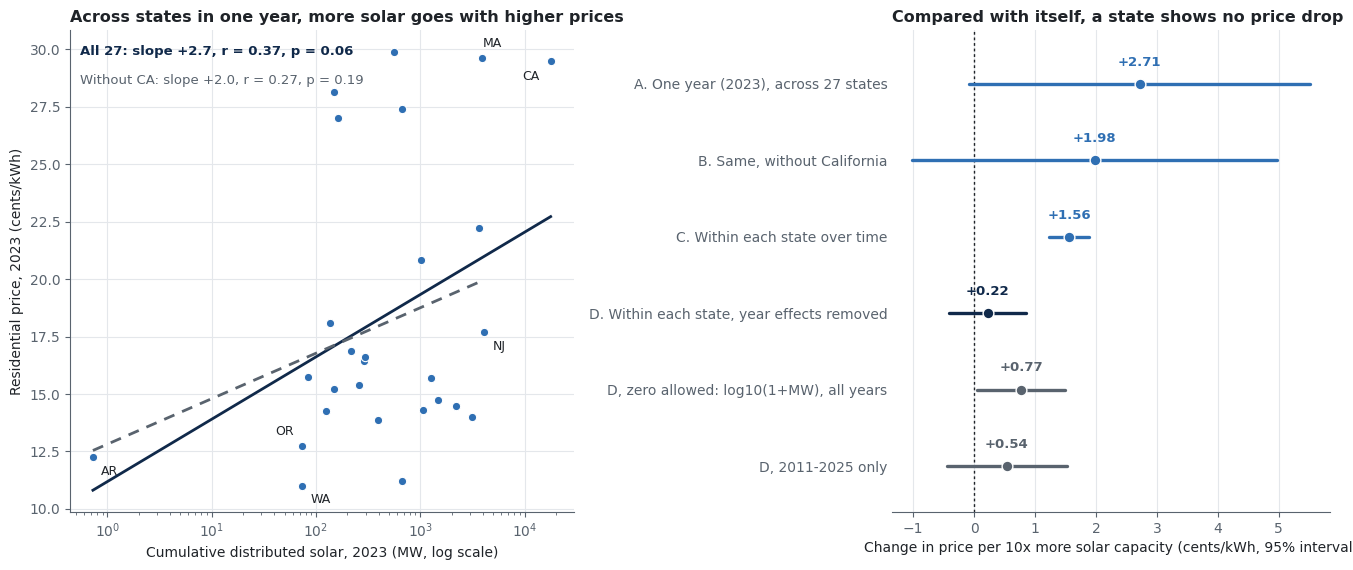

In [21]:
INK, MUTED, GRID, BLUE, DARK = "#1f2328", "#59636e", "#e4e7eb", "#2f6fb3", "#10294a"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "text.color": INK, "figure.facecolor": "white", "axes.facecolor": "white"})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})

# Left: 2023 cross-section
ax1.scatter(d23["mw"], d23["price_cents_kwh"], s=36, color=BLUE, edgecolor="white", linewidth=0.8, zorder=3)
xs = np.linspace(d23["log_mw"].min(), d23["log_mw"].max(), 100)
r_all = stats.linregress(d23["log_mw"], d23["price_cents_kwh"])
d23n = d23[d23["state_id"] != "CA"]
r_no = stats.linregress(d23n["log_mw"], d23n["price_cents_kwh"])
ax1.plot(10 ** xs, r_all.intercept + r_all.slope * xs, color=DARK, lw=2, zorder=2)
xn = np.linspace(d23n["log_mw"].min(), d23n["log_mw"].max(), 100)
ax1.plot(10 ** xn, r_no.intercept + r_no.slope * xn, color=MUTED, lw=2, ls=(0, (4, 3)), zorder=2)
ax1.set_xscale("log")
for s, dx, dy in [("CA", -8, -14), ("MA", 0, 8), ("NJ", 6, -13), ("AR", 6, -13), ("WA", 6, -12), ("OR", -6, 8)]:
    row = d23[d23["state_id"] == s].iloc[0]
    ax1.annotate(s, (row["mw"], row["price_cents_kwh"]), xytext=(dx, dy), textcoords="offset points",
                 ha="right" if dx < 0 else "left", fontsize=9, color=INK)
ax1.text(0.02, 0.97, f"All 27: slope {r_all.slope:+.1f}, r = {r_all.rvalue:.2f}, p = {r_all.pvalue:.2f}",
         transform=ax1.transAxes, va="top", color=DARK, fontsize=9.5, weight="bold")
ax1.text(0.02, 0.91, f"Without CA: slope {r_no.slope:+.1f}, r = {r_no.rvalue:.2f}, p = {r_no.pvalue:.2f}",
         transform=ax1.transAxes, va="top", color=MUTED, fontsize=9.5)
ax1.set_xlabel("Cumulative distributed solar, 2023 (MW, log scale)")
ax1.set_ylabel("Residential price, 2023 (cents/kWh)")
ax1.set_title("Across states in one year, more solar goes with higher prices", loc="left", fontsize=11.5, weight="bold")
ax1.grid(color=GRID, lw=0.8, zorder=0); ax1.set_axisbelow(True)
for sp in ("top", "right"): ax1.spines[sp].set_visible(False)

# Right: estimates, simplest to strictest
rows = [("A. One year (2023), across 27 states", a["slope"], a["lo"], a["hi"], BLUE),
        ("B. Same, without California", b["slope"], b["lo"], b["hi"], BLUE),
        ("C. Within each state over time", c["slope"], c["lo"], c["hi"], BLUE),
        ("D. Within each state, year effects removed", dd["slope"], dd["lo"], dd["hi"], DARK),
        ("D, zero allowed: log10(1+MW), all years", d_log1p["slope"], d_log1p["lo"], d_log1p["hi"], MUTED),
        ("D, 2011-2025 only", d_2011["slope"], d_2011["lo"], d_2011["hi"], MUTED)]
for i, (lab, s, lo, hi, col) in enumerate(rows):
    y = len(rows) - 1 - i
    ax2.plot([lo, hi], [y, y], color=col, lw=2.4, solid_capstyle="round", zorder=3)
    ax2.scatter([s], [y], s=60, color=col, edgecolor="white", zorder=4)
    ax2.text(s, y + 0.2, f"{s:+.2f}", ha="center", va="bottom", fontsize=9.5, color=col, weight="bold")
ax2.axvline(0, color=INK, lw=1, ls=(0, (2, 2)), zorder=1)
ax2.set_yticks(range(len(rows))); ax2.set_yticklabels([r[0] for r in rows][::-1])
ax2.set_xlabel("Change in price per 10x more solar capacity (cents/kWh, 95% interval)")
ax2.set_ylim(-0.6, len(rows) - 0.3); ax2.invert_yaxis() if False else None
ax2.set_title("Compared with itself, a state shows no price drop", loc="left", fontsize=11.5, weight="bold")
ax2.grid(axis="x", color=GRID, lw=0.8, zorder=0); ax2.set_axisbelow(True)
for sp in ("top", "right", "left"): ax2.spines[sp].set_visible(False)
ax2.tick_params(axis="y", length=0)
fig.tight_layout()
fig.savefig(FIG / "p4_price_vs_solar.png", dpi=200, bbox_inches="tight")
plt.show()

## Step 7. Save the numbers

Every number in the report comes from this file, so each claim can be traced to a cell above.

In [22]:
def clean(o):
    if isinstance(o, dict):  return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)):  return int(o)
    return o
(RES / "p4_results.json").write_text(json.dumps(clean(RESULTS), indent=2))
print("Saved", RES / "p4_results.json", "and", FIG / "p4_price_vs_solar.png")

Saved results/p4_results.json and figures/p4_price_vs_solar.png
